# Notebook 04 — Deep Learning with BiLSTM

This notebook trains a word-level bidirectional LSTM on the cleaned review text. Vocabulary and sequence preparation use training data only.

In [1]:
from pathlib import Path
import random, json, warnings
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns
SEED=42; random.seed(SEED); np.random.seed(SEED)
DATA_PATH=Path('data/processed/hotel_reviews_model_ready.csv')
if not DATA_PATH.exists(): DATA_PATH=Path('/home/ubuntu/work_sentiment/sentiment_analysis_submission/data/processed/hotel_reviews_model_ready.csv')
LABELS=['negative','neutral','positive']
df=pd.read_csv(DATA_PATH,encoding='utf-8-sig',dtype=str,keep_default_na=False)
print('Loaded model-ready data:',df.shape)
import torch
from torch import nn
from torch.utils.data import Dataset,DataLoader
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu'); print('device:',device)
MAX_SAMPLES=None
work=df.copy() if MAX_SAMPLES is None else train_test_split(df,train_size=min(MAX_SAMPLES,len(df)),stratify=df['sentiment'],random_state=SEED)[0]
train,val_test=train_test_split(work,test_size=.25,stratify=work['sentiment'],random_state=SEED)
val,test=train_test_split(val_test,test_size=.5,stratify=val_test['sentiment'],random_state=SEED)
MAX_VOCAB=30000; MAX_LEN=80
vocab={'<PAD>':0,'<UNK>':1}
for text in train['review_clean']:
 for tok in text.split():
  if tok not in vocab and len(vocab)<MAX_VOCAB: vocab[tok]=len(vocab)
label_to_id={x:i for i,x in enumerate(LABELS)}
def enc(text):
 ids=[vocab.get(t,1) for t in text.split()[:MAX_LEN]]; return ids+[0]*(MAX_LEN-len(ids))
class Reviews(Dataset):
 def __init__(self,frame): self.x=torch.tensor([enc(x) for x in frame['review_clean']],dtype=torch.long); self.y=torch.tensor([label_to_id[x] for x in frame['sentiment']],dtype=torch.long)
 def __len__(self): return len(self.y)
 def __getitem__(self,i): return self.x[i],self.y[i]

Loaded model-ready data: (397993, 35)


device: cpu


In [2]:
class BiLSTM(nn.Module):
 def __init__(self,vocab_size,emb=64,hidden=48):
  super().__init__(); self.emb=nn.Embedding(vocab_size,emb,padding_idx=0); self.lstm=nn.LSTM(emb,hidden,batch_first=True,bidirectional=True,num_layers=2,dropout=.2); self.drop=nn.Dropout(.35); self.fc=nn.Linear(hidden*2,3)
 def forward(self,x):
  _,(h,_) = self.lstm(self.emb(x)); h=torch.cat([h[-2],h[-1]],dim=1); return self.fc(self.drop(h))
train_loader=DataLoader(Reviews(train),batch_size=1024,shuffle=True); val_loader=DataLoader(Reviews(val),batch_size=2048); test_loader=DataLoader(Reviews(test),batch_size=2048)
model=BiLSTM(len(vocab)).to(device); opt=torch.optim.AdamW(model.parameters(),lr=2e-3,weight_decay=1e-5); loss_fn=nn.CrossEntropyLoss(); best=-1; best_state=None
for epoch in range(1):
 model.train(); total=0
 for xb,yb in train_loader:
  xb,yb=xb.to(device),yb.to(device); opt.zero_grad(); loss=loss_fn(model(xb),yb); loss.backward(); opt.step(); total+=loss.item()
 model.eval(); yp=[]; yt=[]
 with torch.no_grad():
  for xb,yb in val_loader: yp.extend(model(xb.to(device)).argmax(1).cpu().numpy()); yt.extend(yb.numpy())
 score=f1_score(yt,yp,average='macro'); print(f'epoch={epoch+1} loss={total/len(train_loader):.4f} val_macro_f1={score:.4f}')
 if score>best: best=score; best_state={k:v.cpu().clone() for k,v in model.state_dict().items()}
model.load_state_dict(best_state); model.to(device); model.eval(); yp=[]; yt=[]
with torch.no_grad():
 for xb,yb in test_loader: yp.extend(model(xb.to(device)).argmax(1).cpu().numpy()); yt.extend(yb.numpy())
y_true=[LABELS[i] for i in yt]; y_pred=[LABELS[i] for i in yp]
print(classification_report(y_true,y_pred,labels=LABELS,digits=4,zero_division=0))
metrics={'model':'BiLSTM','accuracy':accuracy_score(y_true,y_pred),'macro_f1':f1_score(y_true,y_pred,labels=LABELS,average='macro'),'weighted_f1':f1_score(y_true,y_pred,labels=LABELS,average='weighted')}
Path('artifacts').mkdir(exist_ok=True); Path('artifacts/bilstm_metrics.json').write_text(json.dumps(metrics,indent=2))

epoch=1 loss=0.4030 val_macro_f1=0.8184


              precision    recall  f1-score   support

    negative     0.8214    0.7575    0.7882      6500
     neutral     0.7853    0.6579    0.7160      9910
    positive     0.9103    0.9680    0.9382     33340

    accuracy                         0.8787     49750
   macro avg     0.8390    0.7945    0.8141     49750
weighted avg     0.8738    0.8787    0.8744     49750



127

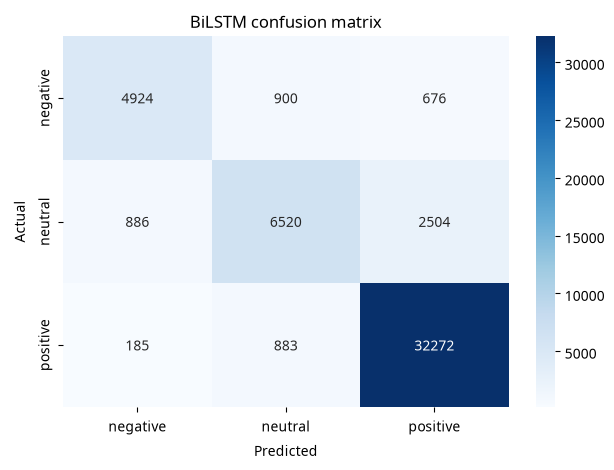

In [3]:
cm=confusion_matrix(y_true,y_pred,labels=LABELS); sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=LABELS,yticklabels=LABELS); plt.title('BiLSTM confusion matrix'); plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.tight_layout(); plt.show()